# 01 — Análise Exploratória de Dados (EDA)

**Objetivo:** investigar a estrutura, a qualidade, as distribuições e as relações entre variáveis de um conjunto de vendas **sintético**, antes de tomar decisões de tratamento.

Ao concluir, você será capaz de: (1) identificar a unidade de observação e o período, (2) diagnosticar valores ausentes e duplicatas, (3) interpretar estatísticas e gráficos, (4) avaliar relações sem confundi-las com causalidade e (5) comunicar limitações dos indicadores.

**Pré-requisito:** conhecimentos básicos de Python e Pandas. **Dados:** `datasets/vendas_exemplo.csv` (49 registros de demonstração). Execute as células **na ordem**, a partir da raiz da biblioteca (a pasta que contém `datasets/` e este notebook). Os gráficos são exibidos na tela; este notebook não grava arquivos em `outputs/`.

> **Nota:** os registros não representam vendas reais. Neste notebook fazemos diagnóstico; decisões de limpeza e exportação são aprofundadas no notebook 02 — ETL e Preparação de Dados.

### Materiais complementares

- [Guia — EDA](./reference_materials/01_analise_exploratoria_de_dados.pdf)
- [Cheat sheet — EDA](./cheat_sheets/cheat_sheet_eda.pdf)

Os arquivos estão nesta mesma pasta da disciplina. Os PDFs complementam, mas não substituem, a execução das células.

## 1. Carregamento e compreensão do dataset

**Granularidade** (unidade de observação) é o que uma linha representa. Aqui cada linha é um **registro de venda no dataset**, com data, região, produto, canal, unidades e preço unitário. Não há identificador de transação; portanto, duas linhas idênticas não provam uma duplicação indevida.

Antes de agregar informações, investigue quantidade de linhas e colunas, tipos, período, categorias e possíveis limitações de chave.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

def preparar_pastas():
    """Localiza a biblioteca e cria as pastas de dados e resultados, se ausentes."""
    atual = Path.cwd().resolve()
    # Aceita execução na raiz da biblioteca ou em uma pasta filha.
    candidatos = [atual, atual.parent]
    raiz = next(
        (p for p in candidatos if (p / 'vendas_exemplo.csv').is_file() or
         (p / 'datasets' / 'vendas_exemplo.csv').is_file()),
        None,
    )
    if raiz is None:
        # Identifica a raiz da biblioteca pelo conjunto de notebooks.
        raiz = next(
            (p for p in candidatos if (p / '01_Analise_Exploratoria_de_Dados.ipynb').is_file()),
            atual,
        )
    dados = raiz / 'datasets'
    saidas = raiz / 'outputs'
    dados.mkdir(parents=True, exist_ok=True)
    saidas.mkdir(parents=True, exist_ok=True)
    return dados, saidas

DATA, OUTPUTS = preparar_pastas()

def conferir_datasets(*nomes):
    ausentes = [nome for nome in nomes if not (DATA / nome).is_file()]
    if ausentes:
        raise FileNotFoundError(
            'Datasets ausentes: ' + ', '.join(ausentes) + '\n'
            + 'Coloque os CSVs fornecidos em: ' + str(DATA.resolve()) + '\n'
            + 'Criar a pasta datasets/ não cria automaticamente os arquivos CSV.'
        )
conferir_datasets('vendas_exemplo.csv')
arquivo = DATA / 'vendas_exemplo.csv'

vendas = pd.read_csv(arquivo, parse_dates=['data'])
print('Dimensões (linhas, colunas):', vendas.shape)
print('Amostra inicial:')
print(vendas.head(5).to_string(index=False))
print('\nTipos de dados:')
print(vendas.dtypes.to_string())
print('\nPeríodo:', vendas['data'].min().date(), 'até', vendas['data'].max().date())
print('Produtos:', sorted(vendas['produto'].dropna().unique()))
print('Canais:', sorted(vendas['canal'].dropna().unique()))
assert {'data', 'regiao', 'produto', 'unidades', 'preco_unitario', 'canal'}.issubset(vendas.columns)

Dimensões (linhas, colunas): (49, 6)
Amostra inicial:
      data   regiao produto  unidades  preco_unitario  canal
2024-01-01    Norte    Café        19            18.0   Loja
2024-01-01      Sul     Chá        38            14.0 Online
2024-01-01  Sudeste    Suco        45             NaN   Loja
2024-01-01 Nordeste    Água        51             7.0 Online
2024-02-01      Sul    Café        31            18.0 Online

Tipos de dados:
data              datetime64[us]
regiao                       str
produto                      str
unidades                   int64
preco_unitario           float64
canal                        str

Período: 2024-01-01 até 2024-12-01
Produtos: ['Café', 'Chá', 'Suco', 'Água']
Canais: ['Loja', 'Online']


**Interpretação:** `shape` mostra dimensões; `dtypes` ajuda a verificar se datas e números foram interpretados adequadamente; `head()` permite uma inspeção rápida. A coluna `data` foi convertida para datetime com `parse_dates`. O dataset cobre meses de 2024, mas essa cobertura não garante uma transação por dia nem representa o mercado real.

**Critério de análise:** sem um ID único de venda, devemos tratar duplicatas como *sinais para investigação*, e não eliminá-las automaticamente.

## 2. Diagnóstico da qualidade dos dados

Investigue **ausência de valores**, **cardinalidade** (quantidade de valores distintos), tipos e **duplicatas exatas**. A ausência de preço impacta a receita calculada; a ausência de região impacta análises geográficas. `isna()` distingue valores ausentes de zeros; `duplicated()` identifica linhas completamente iguais por padrão.

In [2]:
auditoria = pd.DataFrame({
    'tipo': vendas.dtypes.astype(str),
    'ausentes': vendas.isna().sum(),
    'percentual_ausente': (vendas.isna().mean() * 100).round(1),
    'n_unicos': vendas.nunique(dropna=True),
})
print(auditoria.to_string())
print('\nDuplicatas exatas:', int(vendas.duplicated().sum()))
print('Registros com pelo menos um campo ausente:', int(vendas.isna().any(axis=1).sum()))
print('\nExemplos das linhas incompletas:')
print(vendas.loc[vendas.isna().any(axis=1)].to_string(index=False))
print('\nLinhas marcadas como duplicatas (exceto a primeira ocorrência):')
print(vendas.loc[vendas.duplicated()].to_string(index=False))

                          tipo  ausentes  percentual_ausente  n_unicos
data            datetime64[us]         0                 0.0        12
regiao                     str         1                 2.0         4
produto                    str         0                 0.0         4
unidades                 int64         0                 0.0        38
preco_unitario         float64         1                 2.0         4
canal                      str         0                 0.0         2

Duplicatas exatas: 1
Registros com pelo menos um campo ausente: 2

Exemplos das linhas incompletas:
      data  regiao produto  unidades  preco_unitario  canal
2024-01-01 Sudeste    Suco        45             NaN   Loja
2024-04-01     NaN    Café        50            18.0 Online

Linhas marcadas como duplicatas (exceto a primeira ocorrência):
      data regiao produto  unidades  preco_unitario canal
2024-01-01  Norte    Café        19            18.0  Loja


**Como interpretar os achados:**

- Ausência de `preco_unitario`: não é correto equiparar receita desconhecida a receita zero.
- Ausência de `regiao`: análises por região precisam revelar essa limitação, em vez de descartar o registro silenciosamente.
- Duplicata exata: pode indicar erro de integração **ou** duas transações semelhantes; sem chave confiável, não remova automaticamente.
- Cardinalidade: valores distintos ajudam a encontrar categorias raras e inconsistências de escrita, mas uma categoria rara não é necessariamente inválida.

**Boa prática:** documente as regras de qualidade antes de tomar decisões de limpeza. Este notebook mantém todas as linhas originais.

## 3. Estatística descritiva

`describe()` resume contagem de observações válidas, média, desvio-padrão, mínimo, quartis e máximo. Compare medidas de **posição** (média, mediana) e **dispersão** (desvio-padrão, amplitude interquartil — IQR).

- **Média:** usa todos os valores e é sensível a extremos.
- **Mediana (Q2):** valor central dos dados ordenados, mais robusto a extremos.
- **Q1 e Q3:** percentis 25% e 75%; **IQR = Q3 − Q1**.
- **Desvio-padrão:** mede a dispersão em torno da média, na unidade da variável; não é uma medida de qualidade.
- **Assimetria:** descreve a falta de simetria; valores positivos tendem a uma cauda à direita e negativos à esquerda. Seu significado depende do contexto e do tamanho da amostra.

In [3]:
resumo = vendas[['unidades', 'preco_unitario']].describe().round(2)
print(resumo.to_string())

unidades = vendas['unidades']
q1, mediana, q3 = unidades.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
print(f'\nUnidades — média: {unidades.mean():.2f}, mediana: {mediana:.2f}, '
      f'desvio-padrão: {unidades.std():.2f}, assimetria: {unidades.skew():.2f}')
print(f'Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}')
print(f'Limites indicativos pelo critério 1,5 × IQR: [{limite_inferior:.2f}, {limite_superior:.2f}]')
print('Candidatos a valores atípicos (unidades):',
      int(((unidades < limite_inferior) | (unidades > limite_superior)).sum()))

       unidades  preco_unitario
count     49.00           48.00
mean      48.86           12.88
std       14.98            4.07
min       19.00            7.00
25%       39.00           10.75
50%       48.00           14.00
75%       61.00           18.00
max       79.00           18.00

Unidades — média: 48.86, mediana: 48.00, desvio-padrão: 14.98, assimetria: -0.10
Q1: 39.00 | Q3: 61.00 | IQR: 22.00
Limites indicativos pelo critério 1,5 × IQR: [6.00, 94.00]
Candidatos a valores atípicos (unidades): 0


**Cuidado:** o critério de 1,5 × IQR sinaliza observações a inspecionar; não estabelece que sejam erros. O cálculo do desvio-padrão de `Series.std()` usa, por padrão, o divisor `n − 1` (desvio-padrão amostral). A análise descritiva não demonstra relações de causa e efeito.

## 4. Distribuições e observações incomuns

O histograma mostra a forma da distribuição das unidades; o boxplot compara a mediana, a faixa interquartil e potenciais extremos entre produtos. Grupos pequenos ou de tamanhos diferentes exigem cautela na interpretação.

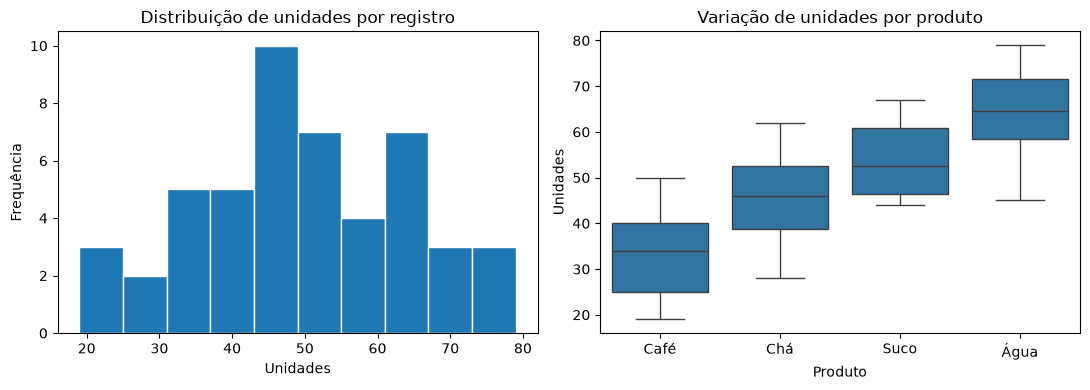

Contagem de registros por produto:
produto
Café    13
Chá     12
Suco    12
Água    12


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(vendas['unidades'].dropna(), bins=10, edgecolor='white')
sns.boxplot(data=vendas, x='produto', y='unidades', ax=axes[1])
axes[0].set(title='Distribuição de unidades por registro', xlabel='Unidades', ylabel='Frequência')
axes[1].set(title='Variação de unidades por produto', xlabel='Produto', ylabel='Unidades')
fig.tight_layout()
plt.show()
print('Contagem de registros por produto:')
print(vendas['produto'].value_counts(dropna=False).to_string())

**Leitura sugerida:** observe concentração, dispersão e sobreposição entre produtos. A altura de um histograma depende da escolha dos intervalos (*bins*); boxplots resumem distribuições, mas escondem detalhes de cada ponto. Evite comparar grupos por totais sem olhar também a quantidade de registros.

## 5. Relações entre variáveis

Use um gráfico de dispersão para observar preço unitário e unidades, distinguindo produtos. A **correlação de Pearson** resume associação *linear* (de −1 a +1) entre pares de valores válidos. A correlação não demonstra causalidade e pode refletir a composição dos grupos ou fatores não medidos.

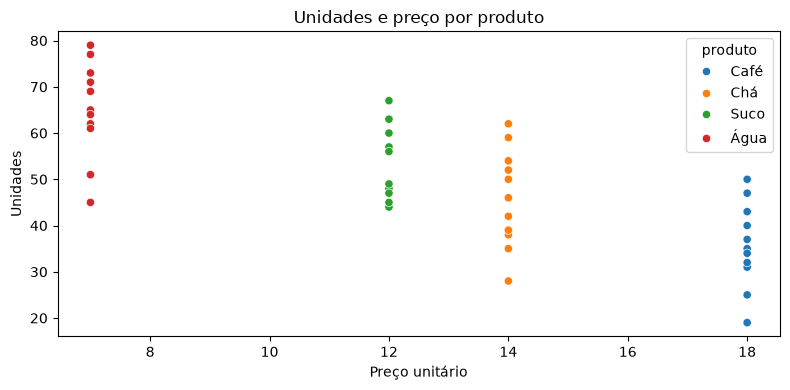

Correlação de Pearson entre unidades e preço: -0.76
Pares válidos usados: 48


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=vendas, x='preco_unitario', y='unidades', hue='produto', ax=ax)
ax.set(title='Unidades e preço por produto', xlabel='Preço unitário', ylabel='Unidades')
fig.tight_layout()
plt.show()
correlacao = vendas[['unidades', 'preco_unitario']].corr().loc['unidades', 'preco_unitario']
print(f'Correlação de Pearson entre unidades e preço: {correlacao:.2f}')
print('Pares válidos usados:', len(vendas[['unidades','preco_unitario']].dropna()))

**Interpretação:** uma correlação negativa neste conjunto não prova que aumentar o preço reduz a quantidade vendida. Os produtos têm preços típicos diferentes, e as observações não representam um experimento controlado. Compare grupos, considere variáveis de contexto e evite extrapolações.

## 6. Indicadores derivados e receita desconhecida

Para fins de demonstração, calculamos `receita = unidades × preco_unitario`, supondo que as unidades informadas correspondem a vendas concretizadas. Essa receita é **calculada**, não confirmada contabilmente.

Um preço ausente gera `NaN` em receita. Ao agregar, `sum()` ignora os valores ausentes e pode retornar zero quando *todos* estão ausentes; `sum(min_count=1)` preserva `NaN` nesse caso. Uma soma com parte dos preços ausentes representa somente **receita conhecida**, não necessariamente a receita total real.

In [6]:
vendas['receita'] = vendas['unidades'] * vendas['preco_unitario']
resumo_produtos = vendas.groupby('produto', dropna=False).agg(
    registros=('produto', 'size'),
    unidades=('unidades', 'sum'),
    registros_sem_preco=('preco_unitario', lambda s: s.isna().sum()),
    receita_conhecida=('receita', lambda s: s.sum(min_count=1)),
)
print(resumo_produtos.to_string())
receita_conhecida = vendas['receita'].sum(min_count=1)
print(f'\nReceita conhecida dos registros com preço: {receita_conhecida:.2f}')
print('Registros sem preço:', int(vendas['preco_unitario'].isna().sum()))

# Caso ilustrativo: todos os valores ausentes em um grupo.
exemplo_sem_receita = pd.Series([float('nan'), float('nan')])
print('Soma padrão com todos ausentes:', exemplo_sem_receita.sum())
print('Soma com min_count=1:', exemplo_sem_receita.sum(min_count=1))

         registros  unidades  registros_sem_preco  receita_conhecida
produto                                                             
Café            13       431                    0             7758.0
Chá             12       551                    0             7714.0
Suco            12       644                    1             7188.0
Água            12       768                    0             5376.0

Receita conhecida dos registros com preço: 28036.00
Registros sem preço: 1
Soma padrão com todos ausentes: 0.0
Soma com min_count=1: nan


**Atenção à linguagem:** se uma parcela da base não tem preço, prefira a expressão **participação na receita conhecida**; não a confunda com participação na receita total efetiva. Não imputamos preços faltantes sem uma justificativa de negócio.

## 7. Exercícios resolvidos

Os exercícios recuperam os principais conceitos e mostram interpretações. Os `assert` verificam propriedades dos cálculos, mas não substituem testes de regras de negócio nem avaliação da procedência dos dados.

### Exercício 1 — localizar registros incompletos

**Enunciado:** conte as linhas com ao menos um valor ausente, calcule o percentual e mostre as observações. Explique por que a ausência de preço e de região pode afetar indicadores diferentes.

In [7]:
incompletos = vendas.loc[vendas.isna().any(axis=1)].copy()
percentual_incompletos = 100 * len(incompletos) / len(vendas)
print(f'{len(incompletos)} de {len(vendas)} registros ({percentual_incompletos:.1f}%) têm ausências.')
print(incompletos[['data', 'regiao', 'produto', 'preco_unitario']].to_string(index=False))
assert len(incompletos) == int(vendas.isna().any(axis=1).sum())
assert 0 <= percentual_incompletos <= 100
print('Interpretação: preços ausentes limitam cálculos de receita; regiões ausentes limitam segmentações regionais.')

2 de 49 registros (4.1%) têm ausências.
      data  regiao produto  preco_unitario
2024-01-01 Sudeste    Suco             NaN
2024-04-01     NaN    Café            18.0
Interpretação: preços ausentes limitam cálculos de receita; regiões ausentes limitam segmentações regionais.


### Exercício 2 — comparar média e mediana

**Enunciado:** calcule média e mediana das unidades. Compare as duas medidas neste dataset e demonstre a sensibilidade da média adicionando um valor extremo a uma **cópia** da série (sem alterar `vendas`).

In [8]:
media = vendas['unidades'].mean()
mediana = vendas['unidades'].median()
print(f'Dados observados — média: {media:.2f}, mediana: {mediana:.2f}; diferença: {media - mediana:+.2f}')

com_extremo = pd.concat([vendas['unidades'], pd.Series([1000])], ignore_index=True)
print(f'Exemplo hipotético com 1.000 unidades — média: {com_extremo.mean():.2f}, '
      f'mediana: {com_extremo.median():.2f}')
assert com_extremo.mean() > media
assert len(vendas) == 49  # Verifica que a base original permanece intacta.
print('Interpretação: a observação hipotética eleva a média mais que a mediana; isso não torna o valor automaticamente inválido.')

Dados observados — média: 48.86, mediana: 48.00; diferença: +0.86
Exemplo hipotético com 1.000 unidades — média: 67.88, mediana: 48.50
Interpretação: a observação hipotética eleva a média mais que a mediana; isso não torna o valor automaticamente inválido.


### Exercício 3 — auditoria de indicadores

**Enunciado:** informe o percentual de linhas incompletas, o produto com mais unidades e a participação desse produto na **receita conhecida**. Verifique a existência de preços ausentes antes de comunicar a participação.

In [9]:
base = vendas.copy()
base['receita_calc'] = base['unidades'] * base['preco_unitario']
linhas_incompletas = base.isna().any(axis=1).mean() * 100
por_produto = base.groupby('produto', dropna=False).agg(
    unidades=('unidades', 'sum'),
    receita_conhecida=('receita_calc', lambda s: s.sum(min_count=1)),
    registros_sem_preco=('preco_unitario', lambda s: s.isna().sum()),
)
produto_lider = por_produto['unidades'].idxmax()
total_conhecido = por_produto['receita_conhecida'].sum(min_count=1)
participacao_conhecida = (por_produto.loc[produto_lider, 'receita_conhecida'] / total_conhecido * 100
                          if pd.notna(total_conhecido) and total_conhecido != 0 else float('nan'))
print(f'Linhas com ausências: {linhas_incompletas:.1f}%')
print(f'Maior volume de unidades: {produto_lider} ({por_produto.loc[produto_lider, "unidades"]})')
print(f'Participação na receita conhecida: {participacao_conhecida:.1f}%')
print('Total de registros com preço ausente:', int(por_produto['registros_sem_preco'].sum()))
assert 0 <= linhas_incompletas <= 100
assert pd.isna(participacao_conhecida) or 0 <= participacao_conhecida <= 100
assert por_produto['unidades'].sum() == base['unidades'].sum()
print('Limitação: a participação é calculada sobre valores conhecidos; o total efetivo pode ser maior.')

Linhas com ausências: 4.1%
Maior volume de unidades: Água (768)
Participação na receita conhecida: 19.2%
Total de registros com preço ausente: 1
Limitação: a participação é calculada sobre valores conhecidos; o total efetivo pode ser maior.


### Exercício 4 — mini-relatório exploratório

**Enunciado:** produza um resumo verificável com abrangência temporal, quantidade de observações, completude, duplicatas exatas, concentração de unidades por produto e ressalvas sobre os dados. Não limpe nem exporte dados.

In [10]:
n_registros = len(vendas)
qtde_ausencias = int(vendas.isna().any(axis=1).sum())
qtde_duplicatas = int(vendas.duplicated(subset=['data', 'regiao', 'produto', 'unidades', 'preco_unitario', 'canal']).sum())
unidades_por_produto = vendas.groupby('produto')['unidades'].sum().sort_values(ascending=False)
lider = unidades_por_produto.index[0]
porcentagem_unidades_lider = 100 * unidades_por_produto.iloc[0] / unidades_por_produto.sum()

print('MINI-RELATÓRIO EXPLORATÓRIO')
print(f'Período observado: {vendas["data"].min().date()} a {vendas["data"].max().date()}')
print(f'Linhas: {n_registros} | Com alguma ausência: {qtde_ausencias} | Duplicatas exatas: {qtde_duplicatas}')
print(f'Maior volume por produto: {lider} ({porcentagem_unidades_lider:.1f}% das unidades)')
print('Limitações: dados sintéticos; duplicação sem ID transacional; receita incompleta quando falta preço.')
assert n_registros > 0 and unidades_por_produto.size > 0
assert abs(unidades_por_produto.sum() - vendas['unidades'].sum()) < 1e-9
assert 0 <= porcentagem_unidades_lider <= 100

MINI-RELATÓRIO EXPLORATÓRIO
Período observado: 2024-01-01 a 2024-12-01
Linhas: 49 | Com alguma ausência: 2 | Duplicatas exatas: 1
Maior volume por produto: Água (32.1% das unidades)
Limitações: dados sintéticos; duplicação sem ID transacional; receita incompleta quando falta preço.


## 8. Boas práticas e erros comuns

- **Granularidade:** não agregue medidas sem entender o significado de cada linha.
- **Duplicatas:** diferencie registros iguais de transações comprovadamente repetidas.
- **Valores ausentes:** `NaN` não é zero; documente como eles afetam cada indicador.
- **Estatísticas:** relacione média, mediana, quartis e dispersão às perguntas de negócio.
- **Gráficos:** informe unidade de medida, categorias e contexto; observe tamanhos dos grupos.
- **Relações:** correlação não implica causalidade; associação entre grupos pode refletir diferenças de composição.
- **Escopo:** conclusões deste exercício descrevem somente dados sintéticos; não são projeções de mercado.
- **Reprodutibilidade:** mantenha a leitura de `datasets/` e, se futuramente salvar resultados, use `outputs/`.

## 9. Consulta Rápida

| Objetivo | Comando de referência | Observação |
|---|---|---|
| Tamanho da base | `df.shape` | Retorna `(linhas, colunas)` |
| Amostra inicial | `df.head()` | Não substitui inspeção da base inteira |
| Tipos | `df.dtypes` ou `df.info()` | Identifique datas e categorias |
| Período | `df['data'].min(), df['data'].max()` | Coluna precisa estar como datetime |
| Ausentes por coluna | `df.isna().sum()` | Zero e string vazia não são necessariamente `NaN` |
| % de ausentes | `100 * df.isna().mean()` | Percentual por coluna |
| Linhas incompletas | `df[df.isna().any(axis=1)]` | Ao menos um campo ausente |
| Duplicatas exatas | `df.duplicated().sum()` | Não prova erro sem chave adequada |
| Valores distintos | `df['produto'].nunique()` | Para cardinalidade |
| Frequências | `df['produto'].value_counts(dropna=False)` | Pode incluir ausentes |
| Estatística resumida | `df['unidades'].describe()` | Posição e dispersão |
| Quartis e IQR | `s.quantile([.25, .5, .75])` | IQR = Q3 − Q1 |
| Correlação | `df[['x','y']].corr()` | Associação linear de Pearson por padrão |
| Soma com mínimo válido | `s.sum(min_count=1)` | Preserva `NaN` se todos forem ausentes |
| Agregação | `df.groupby('produto')['unidades'].sum()` | Defina a granularidade primeiro |
| Histograma | `sns.histplot(data=df, x='unidades')` | Depende dos intervalos |
| Boxplot | `sns.boxplot(data=df, x='produto', y='unidades')` | Destaca quartis e possíveis extremos |
| Dispersão | `sns.scatterplot(data=df, x='preco_unitario', y='unidades')` | Observe grupos e observações atípicas |

**Sequência útil:** compreender a unidade de observação → inspecionar → auditar qualidade → descrever distribuições → explorar relações → calcular indicadores → registrar limitações.

**Próxima etapa da disciplina:** no notebook 02, aprofundar procedimentos de ETL e decisões de tratamento, sem confundir investigação exploratória com limpeza automática.

## 10. Aprofundamento v2 — auditoria reproduzível e interpretação responsável

**Pergunta:** quais campos possuem maior proporção de dados ausentes? Essa ausência pode afetar um indicador de receita? Um gráfico exploratório não identifica causalidade; a unidade observacional e o mecanismo de ausência devem ser descritos antes das conclusões.

**Exercício resolvido:** construir uma tabela ordenada de completude, sem preencher artificialmente preços desconhecidos. Confira os invariantes de proporção.

In [11]:
from pathlib import Path
import pandas as pd
v2_vendas = pd.read_csv(DATA / 'vendas_exemplo.csv')
v2_completude = pd.DataFrame({
    'campo': v2_vendas.columns,
    'ausentes': v2_vendas.isna().sum().to_numpy(),
    'taxa_ausentes': v2_vendas.isna().mean().to_numpy(),
}).sort_values('taxa_ausentes', ascending=False)
assert v2_completude['taxa_ausentes'].between(0, 1).all()
assert v2_completude['ausentes'].sum() == v2_vendas.isna().sum().sum()
print(v2_completude.to_string(index=False, formatters={'taxa_ausentes':'{:.1%}'.format}))

         campo  ausentes taxa_ausentes
        regiao         1          2.0%
preco_unitario         1          2.0%
          data         0          0.0%
       produto         0          0.0%
      unidades         0          0.0%
         canal         0          0.0%


**Interpretação orientada:** a taxa deve sempre trazer denominador. Para qualquer receita que contenha preço ausente, reporte *receita observável* e *cobertura das observações*, nunca preencha `NaN` com zero sem justificativa de negócio.

**Checklist:** granularidade clara; origem sintética; tipos e duplicatas verificados; ausências quantificadas; inferências causais não extrapoladas.